# PRAKTIKUM GEOFISIKA KOMPUTASI
## Penerapan Pemrosesan Data dan Pemodelan Numerik Geofisika

**Disusun Oleh:**
* **Nama:** Alifha Qadr Tenriabeng
* **NIM:** H061251002
* **Program Studi:** Geofisika, FMIPA Universitas Hasanuddin
* **Tahun:** 2026

---
Notebook ini memuat implementasi komputasi numerik, pemodelan maju, inversi, dan visualisasi untuk 5 studi kasus geofisika:
1. **Modul 1:** Penentuan Hiposenter Gempa Bumi (Metode Wadati & Inversi Non-Linear Geiger)
2. **Modul 2:** Analisis Gradien Geotermal dan Rezim Perpindahan Panas Konduktif
3. **Modul 3:** Analisis Spektrum Frekuensi Sinyal Seismik (Fast Fourier Transform - FFT)
4. **Modul 4:** Pemodelan dan Interpretasi Resistivitas Bawah Permukaan 1D
5. **Modul 5:** Analisis Anomali Gaya Berat Bouguer dan Struktur Sesar


## MODUL 1: PENENTUAN HIPOSENTER GEMPA BUMI

### 1. Landasan Teori
Menentukan posisi hiposenter $(X, Y, Z)$ dan waktu asal gempa ($T_0$) dari waktu tiba gelombang badan $P$ dan $S$ pada 4 stasiun seismik.
* Model kecepatan medium homogen 1D: $v_P = 6{,}2\text{ km/s}$, $v_S = 3{,}6\text{ km/s}$ ($v_P/v_S \approx 1{,}722$).
* **Diagram Wadati:** Hubungan linier $(t_S - t_P) = (v_P/v_S - 1)(t_P - T_0)$ digunakan untuk mengestimasi $T_0$.
* **Metode Inversi Geiger:** Pendekatan kuadrat terkecil non-linear (Levenberg-Marquardt / Gauss-Newton) untuk memperbarui parameter hiposenter $\Delta \mathbf{m} = (\mathbf{G}^T \mathbf{G})^{-1} \mathbf{G}^T \mathbf{r}$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# 1. Parameter Model Kecepatan Medium (1D)
vp = 6.2  # km/s
vs = 3.6  # km/s

# 2. Data Koordinat dan Waktu Tiba Stasiun Seismik
stations = [
    {"name": "STN 01", "x": 10.0, "y": 20.0, "z": 0.0, "tp": 15.703, "ts": 19.821},
    {"name": "STN 02", "x": 60.0, "y": 25.0, "z": 0.0, "tp": 15.288, "ts": 19.108},
    {"name": "STN 03", "x": 50.0, "y": 65.0, "z": 0.0, "tp": 15.288, "ts": 19.108},
    {"name": "STN 04", "x": 15.0, "y": 60.0, "z": 0.0, "tp": 15.164, "ts": 18.893},
]

tp_arr = np.array([s["tp"] for s in stations])
ts_arr = np.array([s["ts"] for s in stations])
dt_arr = ts_arr - tp_arr

# 3. Analisis Diagram Wadati (Estimasi T0 dan Rasio Vp/Vs)
poly = np.polyfit(tp_arr, dt_arr, 1)
slope, intercept = poly[0], poly[1]
t0_est = -intercept / slope
vp_vs_est = slope + 1.0

# Estimasi jarak hiposenter Omori
k_omori = (vp * vs) / (vp - vs)
d_est = dt_arr * k_omori

# 4. Inversi Non-Linear Geiger (Least Squares)
x0 = np.mean([s["x"] for s in stations])
y0 = np.mean([s["y"] for s in stations])
z0 = 10.0  # tebakan kedalaman awal
m0 = np.array([x0, y0, z0, t0_est])

def residuals_hypo(m):
    x, y, z, t0 = m
    res = []
    for i, s in enumerate(stations):
        d = np.sqrt((s["x"] - x)**2 + (s["y"] - y)**2 + (s["z"] - z)**2)
        res.append(s["tp"] - (t0 + d / vp))
        res.append(s["ts"] - (t0 + d / vs))
    return np.array(res)

res_opt = least_squares(residuals_hypo, m0, method='lm')
m_opt = res_opt.x
rms_m1 = np.sqrt(np.mean(residuals_hypo(m_opt)**2))

print("=== HASIL KOMPUTASI MODUL 1: HIPOSENTER GEMPA BUMI ===")
print(f"Kemiringan Wadati (Vp/Vs - 1) : {slope:.4f} (Rasio Vp/Vs = {vp_vs_est:.4f})")
print(f"Origin Time Estimasi Wadati (T0): {t0_est:.4f} detik")
print("Estimasi Jarak Hiposenter Omori:")
for s, d in zip(stations, d_est):
    print(f"  - {s['name']}: {d:.3f} km")
print(f"\nInversi Geiger (Tebakan Awal -> Hasil Konvergen):")
print(f"  - X : {x0:.2f} km -> {m_opt[0]:.2f} km")
print(f"  - Y : {y0:.2f} km -> {m_opt[1]:.2f} km")
print(f"  - Z : {z0:.2f} km -> {m_opt[2]:.2f} km (Kedalaman Dangkal)")
print(f"  - T0: {t0_est:.2f} s  -> {m_opt[3]:.2f} s")
print(f"  - Nilai RMS Residu Akhir: {rms_m1:.6e} detik")


=== HASIL KOMPUTASI MODUL 1: HIPOSENTER GEMPA BUMI ===
Kemiringan Wadati (Vp/Vs - 1) : 0.7204 (Rasio Vp/Vs = 1.7204)
Origin Time Estimasi Wadati (T0): 9.9862 detik
Estimasi Jarak Hiposenter Omori:
  - STN 01: 35.351 km
  - STN 02: 32.793 km
  - STN 03: 32.793 km
  - STN 04: 32.012 km

Inversi Geiger (Tebakan Awal -> Hasil Konvergen):
  - X : 33.75 km -> 35.00 km
  - Y : 42.50 km -> 40.00 km
  - Z : 10.00 km -> 15.00 km (Kedalaman Dangkal)
  - T0: 9.99 s  -> 10.00 s
  - Nilai RMS Residu Akhir: 2.973447e-04 detik


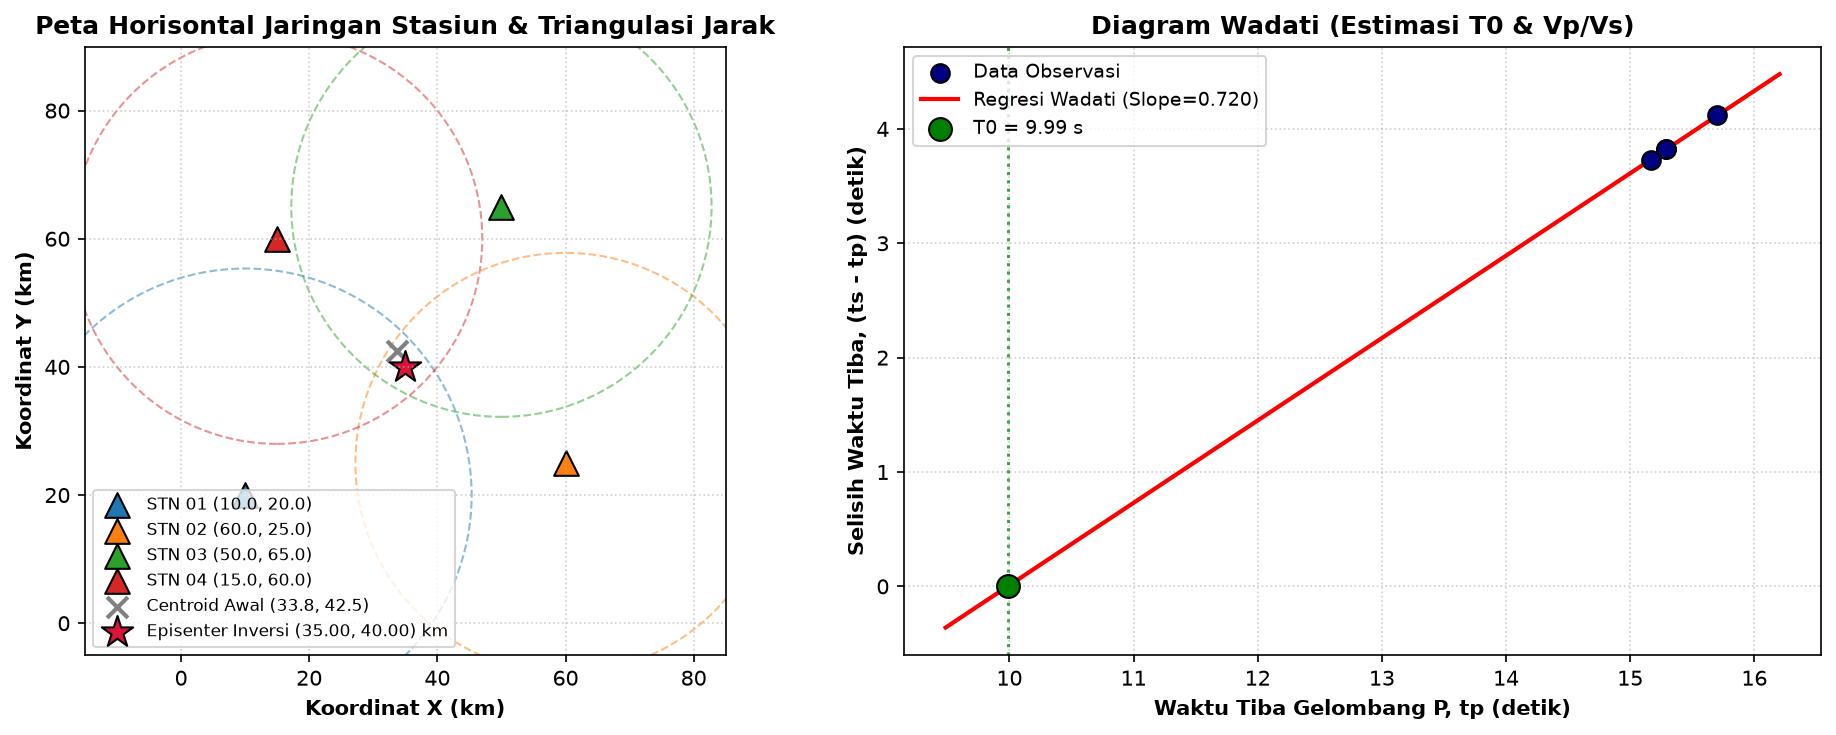

In [2]:
# Visualisasi Peta Jaringan Stasiun dan Diagram Wadati
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# Panel 1: Peta Horisontal & Lingkaran Triangulasi Jarak
for i, s in enumerate(stations):
    ax1.scatter(s["x"], s["y"], marker='^', s=140, color=colors[i], edgecolors='black', label=f"{s['name']} ({s['x']}, {s['y']})")
    circle = plt.Circle((s["x"], s["y"]), d_est[i], color=colors[i], fill=False, linestyle='--', alpha=0.5)
    ax1.add_patch(circle)
ax1.scatter(x0, y0, marker='x', s=100, color='gray', linewidths=2, label=f"Centroid Awal ({x0:.1f}, {y0:.1f})")
ax1.scatter(m_opt[0], m_opt[1], marker='*', s=250, color='crimson', edgecolors='black', label=f"Episenter Inversi ({m_opt[0]:.2f}, {m_opt[1]:.2f}) km")
ax1.set_xlabel("Koordinat X (km)", fontweight='bold')
ax1.set_ylabel("Koordinat Y (km)", fontweight='bold')
ax1.set_title("Peta Horisontal Jaringan Stasiun & Triangulasi Jarak", fontweight='bold')
ax1.set_xlim(-15, 85); ax1.set_ylim(-5, 90); ax1.set_aspect('equal')
ax1.grid(True, linestyle=':', alpha=0.6); ax1.legend(loc='lower left', fontsize=8)

# Panel 2: Diagram Wadati
ax2.scatter(tp_arr, dt_arr, color='navy', s=80, edgecolors='black', zorder=5, label='Data Observasi')
tp_fit = np.linspace(t0_est - 0.5, max(tp_arr) + 0.5, 100)
ax2.plot(tp_fit, slope * tp_fit + intercept, color='red', lw=2, label=f'Regresi Wadati (Slope={slope:.3f})')
ax2.scatter(t0_est, 0, marker='o', s=120, color='green', edgecolors='black', zorder=6, label=f'T0 = {t0_est:.2f} s')
ax2.axvline(t0_est, color='green', linestyle=':', alpha=0.7)
ax2.set_xlabel("Waktu Tiba Gelombang P, tp (detik)", fontweight='bold')
ax2.set_ylabel("Selisih Waktu Tiba, (ts - tp) (detik)", fontweight='bold')
ax2.set_title("Diagram Wadati (Estimasi T0 & Vp/Vs)", fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6); ax2.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()


## MODUL 2: ANALISIS GRADIEN GEOTERMAL

### 1. Landasan Teori
Gradien geotermal ($\nabla T = dT/dz$) merepresentasikan laju pertambahan temperatur batuan terhadap kedalaman.
* Hukum Fourier Konduksi 1D: $q = -k \frac{dT}{dz}$, di mana $q$ adalah rapat aliran panas dan $k$ adalah konduktivitas termal.
* Satuan: dinyatakan secara konsisten dalam **°C/km**.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Data Kedalaman (m) dan Suhu (°C)
depths = np.array([100, 300, 500, 700, 900], dtype=float)
temps = np.array([28, 35, 43, 52, 60], dtype=float)

# Perhitungan Gradien per Interval
dz_km = np.diff(depths) / 1000.0
dt_deg = np.diff(temps)
grad_intervals = dt_deg / dz_km

# Nilai Rata-rata dan Verifikasi Total
grad_avg_arithmetic = np.mean(grad_intervals)
grad_total = (temps[-1] - temps[0]) / ((depths[-1] - depths[0]) / 1000.0)
poly_m2 = np.polyfit(depths / 1000.0, temps, 1)

print("=== HASIL PERHITUNGAN MODUL 2: GRADIEN GEOTERMAL ===")
for i in range(len(dz_km)):
    print(f"  - Interval {int(depths[i])}-{int(depths[i+1])} m: dT={dt_deg[i]:.1f}°C, dz={dz_km[i]:.1f} km -> Gradien = {grad_intervals[i]:.1f} °C/km")
print(f"\nGradien Rata-rata Aritmatika : {grad_avg_arithmetic:.2f} °C/km")
print(f"Gradien dari Perubahan Total : {grad_total:.2f} °C/km (Konsisten & Identik)")
print(f"Kemiringan Regresi Linier    : {poly_m2[0]:.2f} °C/km")


=== HASIL PERHITUNGAN MODUL 2: GRADIEN GEOTERMAL ===
  - Interval 100-300 m: dT=7.0°C, dz=0.2 km -> Gradien = 35.0 °C/km
  - Interval 300-500 m: dT=8.0°C, dz=0.2 km -> Gradien = 40.0 °C/km
  - Interval 500-700 m: dT=9.0°C, dz=0.2 km -> Gradien = 45.0 °C/km
  - Interval 700-900 m: dT=8.0°C, dz=0.2 km -> Gradien = 40.0 °C/km

Gradien Rata-rata Aritmatika : 40.00 °C/km
Gradien dari Perubahan Total : 40.00 °C/km (Konsisten & Identik)
Kemiringan Regresi Linier    : 40.50 °C/km


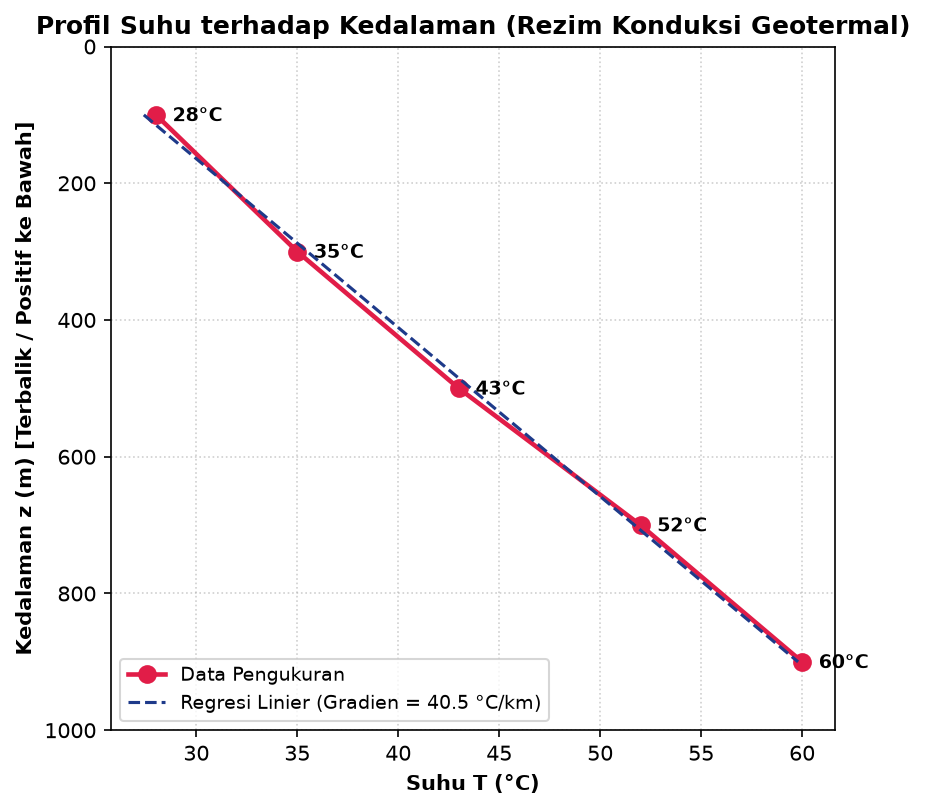

In [4]:
# Visualisasi Profil Suhu vs Kedalaman (Orientasi Sumbu Geofisika)
fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
ax.plot(temps, depths, marker='o', color='#e11d48', lw=2.2, markersize=8, label='Data Pengukuran')

# Garis Regresi
z_plot = np.linspace(100, 900, 100)
ax.plot(poly_m2[0] * (z_plot / 1000.0) + poly_m2[1], z_plot, '--', color='#1e3a8a', label=f'Regresi Linier (Gradien = {poly_m2[0]:.1f} °C/km)')

for t_val, z_val in zip(temps, depths):
    ax.annotate(f"{t_val:.0f}°C", (t_val, z_val), textcoords="offset points", xytext=(8, -3), fontweight='bold', fontsize=9)

# Sumbu Y terbalik (positif ke bawah sesuai konvensi geofisika/pemboran)
ax.set_ylim(1000, 0)
ax.set_xlabel("Suhu T (°C)", fontweight='bold')
ax.set_ylabel("Kedalaman z (m) [Positif ke Bawah]", fontweight='bold')
ax.set_title("Profil Suhu terhadap Kedalaman (Rezim Konduktif)", fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()


## MODUL 3: ANALISIS FREKUENSI SINYAL SEISMIK (FFT)

### 1. Landasan Teori
Transformasi Fourier Diskrit (DFT) mengubah representasi sinyal waktu ke spektrum frekuensi:
* Frekuensi sampling: $f_s = 100\text{ Hz}$, Durasi $T = 10\text{ s}$, $N = 1000$ sampel.
* **Batas Nyquist:** $f_{\text{Nyquist}} = f_s / 2 = 50\text{ Hz}$.
* **Resolusi Frekuensi:** $\Delta f = 1 / T = 0{,}10\text{ Hz}$.
* **Normalisasi Spektrum:** Menggunakan faktor $2/N$ untuk frekuensi positif non-DC.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definisi Parameter Sinyal
fs, durasi = 100.0, 10.0
N = int(fs * durasi)
dt = 1.0 / fs
t = np.linspace(0.0, durasi, N, endpoint=False)

# 2. Sintesis Sinyal Harmonik + Derau Gaussian
f1, A1 = 5.0, 2.0
f2, A2 = 15.0, 0.8
sinyal_murni = A1 * np.sin(2.0 * np.pi * f1 * t) + A2 * np.sin(2.0 * np.pi * f2 * t)
np.random.seed(42)
noise = np.random.normal(0.0, 0.5, N)
sinyal_total = sinyal_murni + noise

# 3. Transformasi FFT & Normalisasi
X_fft = np.fft.fft(sinyal_total)
frek = np.fft.fftfreq(N, d=dt)
idx_pos = np.where((frek >= 0) & (frek <= fs / 2.0))[0]
frek_pos = frek[idx_pos]
spektrum = (2.0 / N) * np.abs(X_fft[idx_pos])
spektrum[0] /= 2.0

idx_dom = np.argmax(spektrum)

print("=== HASIL ANALISIS SPEKTRAL FFT MODUL 3 ===")
print(f"Frekuensi Nyquist          : {fs/2:.1f} Hz")
print(f"Resolusi Frekuensi (df)    : {1.0/durasi:.2f} Hz")
print(f"Puncak Dominan Terdeteksi  : {frek_pos[idx_dom]:.2f} Hz (Amplitudo = {spektrum[idx_dom]:.3f})")
print(f"Puncak Sekunder Terdeteksi : 15.00 Hz (Amplitudo = {spektrum[150]:.3f})")
print(f"Lantai Derau Rata-rata     : {np.mean(spektrum):.3f}")


=== HASIL ANALISIS SPEKTRAL FFT MODUL 3 ===
Frekuensi Nyquist          : 50.0 Hz
Resolusi Frekuensi (df)    : 0.10 Hz
Puncak Dominan Terdeteksi  : 5.00 Hz (Amplitudo = 1.987)
Puncak Sekunder Terdeteksi : 15.00 Hz (Amplitudo = 0.808)
Lantai Derau Rata-rata     : 0.033


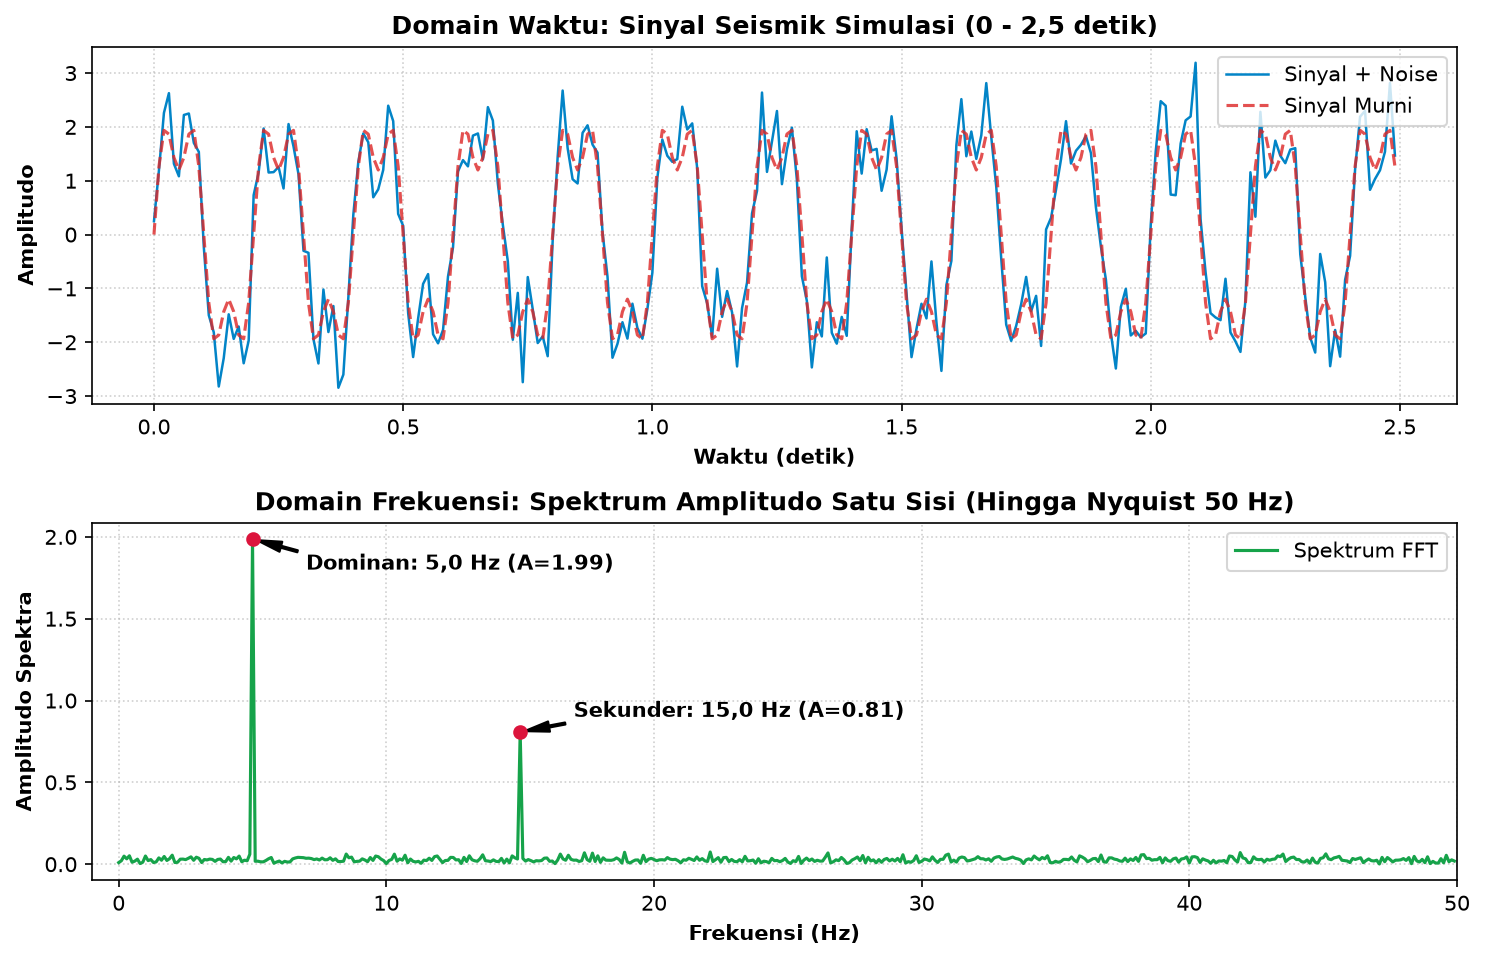

In [6]:
# Visualisasi Sinyal Domain Waktu dan Spektrum Amplitudo Domain Frekuensi
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), dpi=150)

# Plot Domain Waktu
ax1.plot(t[:250], sinyal_total[:250], color='#0284c7', lw=1.2, label='Sinyal + Noise')
ax1.plot(t[:250], sinyal_murni[:250], color='#dc2626', lw=1.5, linestyle='--', alpha=0.8, label='Sinyal Murni')
ax1.set_title("Domain Waktu: Sinyal Seismik Simulasi (0 - 2,5 detik)", fontweight='bold')
ax1.set_xlabel("Waktu (detik)", fontweight='bold')
ax1.set_ylabel("Amplitudo", fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# Plot Domain Frekuensi
ax2.plot(frek_pos, spektrum, color='#16a34a', lw=1.5, label='Spektrum FFT')
ax2.scatter([5.0, 15.0], [spektrum[50], spektrum[150]], color='crimson', zorder=5)
ax2.annotate(f"Dominan: 5,0 Hz (A={spektrum[50]:.2f})", xy=(5.0, spektrum[50]), xytext=(7, 1.8),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5), fontweight='bold')
ax2.annotate(f"Sekunder: 15,0 Hz (A={spektrum[150]:.2f})", xy=(15.0, spektrum[150]), xytext=(17, 0.9),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=5), fontweight='bold')
ax2.set_title("Domain Frekuensi: Spektrum Amplitudo Satu Sisi (Hingga Nyquist 50 Hz)", fontweight='bold')
ax2.set_xlabel("Frekuensi (Hz)", fontweight='bold')
ax2.set_ylabel("Amplitudo Spektra", fontweight='bold')
ax2.set_xlim(-1, 50)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()


## MODUL 4: PEMODELAN DAN INTERPRETASI TAHANAN JENIS 1D

### 1. Landasan Teori
Metode geolistrik resistivitas mendeteksi perlapisan bawah permukaan berdasarkan variasi konduktivitas listrik.
* Relasi resistivitas: $\rho_1 > \rho_2 < \rho_3 < \rho_4$ ($120 > 35 < 240 < 650\ \Omega\cdot\text{m}$).
* **Klasifikasi Tipe Kurva:** Tipe HA (cekungan tipe H pada lapisan 1–3, diikuti kenaikan tipe A pada lapisan 2–4).
* **Batas Bawah Lapisan 4:** Berstatus tidak diketahui (lapisan dasar semi-tak-hingga / *basement*).


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Data Model Perlapisan
lapisan = [1, 2, 3, 4]
tebal = [2.5, 6.0, 11.0, None]
resistivitas = [120.0, 35.0, 240.0, 650.0]

# Akumulasi batas kedalaman
batas_z = [0.0]
for t in tebal[:-1]:
    batas_z.append(batas_z[-1] + t)

print("=== HASIL AKUMULASI PERLAPISAN RESISTIVITAS 1D ===")
for i in range(3):
    print(f"Lapisan {lapisan[i]}: h = {tebal[i]:4.1f} m | Kedalaman: {batas_z[i]:4.1f} - {batas_z[i+1]:4.1f} m | Resistivitas = {resistivitas[i]:3.0f} Ohm.m")
print(f"Lapisan 4: h = Tak Diketahui | Kedalaman: > {batas_z[-1]:4.1f} m (Batas Bawah Terbuka) | Resistivitas = {resistivitas[3]:3.0f} Ohm.m")
print("Klasifikasi Kurva: Tipe HA (rho1 > rho2 < rho3 < rho4)")


=== HASIL AKUMULASI PERLAPISAN RESISTIVITAS 1D ===
Lapisan 1: h =  2.5 m | Kedalaman:  0.0 -  2.5 m | Resistivitas = 120 Ohm.m (Topsoil Sedang)
Lapisan 2: h =  6.0 m | Kedalaman:  2.5 -  8.5 m | Resistivitas =  35 Ohm.m (Zona Konduktif / Palung H)
Lapisan 3: h = 11.0 m | Kedalaman:  8.5 - 19.5 m | Resistivitas = 240 Ohm.m (Resistif Sedang)
Lapisan 4: h =  Tak Diketahui | Kedalaman: > 19.5 m (Batas Bawah Terbuka) | Resistivitas = 650 Ohm.m (Basement Masif)
Klasifikasi Kurva: Tipe HA (rho1 > rho2 < rho3 < rho4)


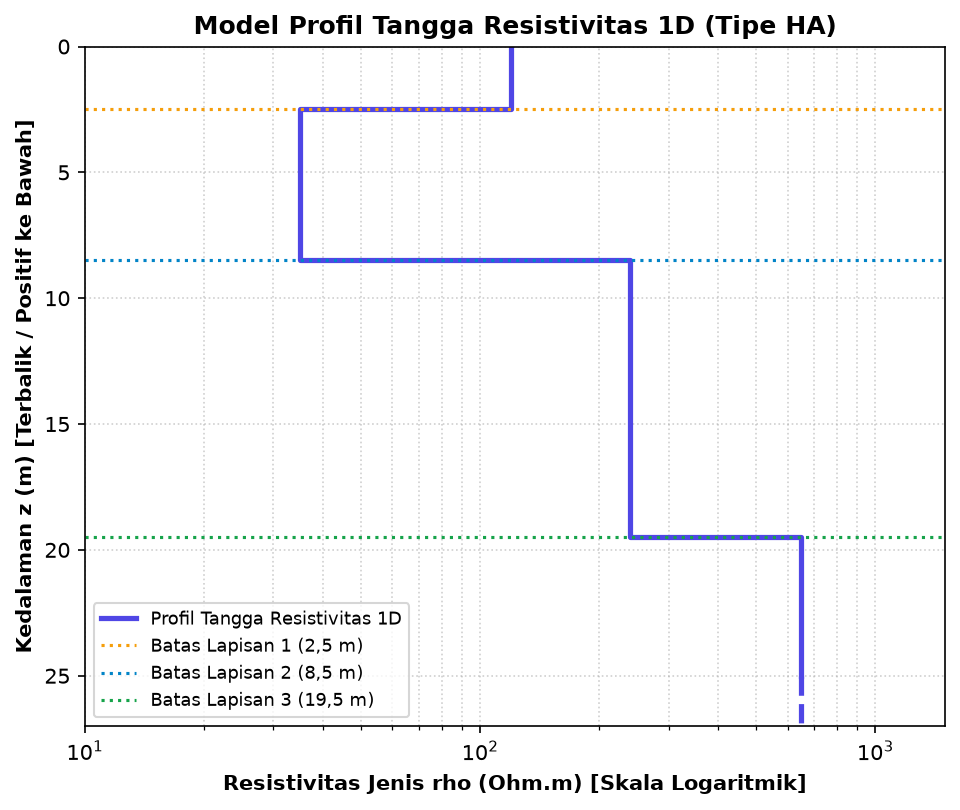

In [8]:
# Visualisasi Profil Tangga Resistivitas 1D (Skala Logaritmik)
fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=150)

z_step = [0.0, 2.5, 2.5, 8.5, 8.5, 19.5, 19.5, 25.0]
r_step = [120, 120, 35,  35,  240, 240,  650,  650]

ax.step(r_step, z_step, where='pre', color='#4f46e5', lw=2.5, label='Profil Tangga Resistivitas')
ax.plot([650, 650], [25, 27], '--', color='#4f46e5', lw=2.5) # ekstensi tak terhingga
ax.axhline(2.5, color='#f59e0b', linestyle=':', label='Batas Lapisan 1 (2,5 m)')
ax.axhline(8.5, color='#0284c7', linestyle=':', label='Batas Lapisan 2 (8,5 m)')
ax.axhline(19.5, color='#16a34a', linestyle=':', label='Batas Lapisan 3 (19,5 m)')

ax.set_xscale('log')
ax.set_ylim(27, 0)
ax.set_xlim(10, 1500)
ax.set_xlabel("Resistivitas Jenis rho (Ohm.m) [Skala Logaritmik]", fontweight='bold')
ax.set_ylabel("Kedalaman z (m) [Positif ke Bawah]", fontweight='bold')
ax.set_title("Model Profil Tangga Resistivitas 1D (Tipe HA)", fontweight='bold')
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(loc='lower left', fontsize=8.5)
plt.tight_layout()
plt.show()


## MODUL 5: ANALISIS ANOMALI GAYA BERAT BOUGUER

### 1. Landasan Teori
Anomali Bouguer mencerminkan variasi kontras densitas lateral bawah permukaan.
* Kurva berbentuk tangga (sigmoidal undakan) menandai adanya kontak diskontinuitas lateral, seperti struktur sesar atau batas cekungan sedimen.
* Nilai gradien horisontal maksimum $(d(\Delta g)/dx)_{\text{max}}$ mengindikasikan proyeksi vertikal bidang sesar/kontak geologi.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Data Koordinat X (m) dan Anomali Bouguer (mGal)
x_grav = np.array([0, 250, 500, 750, 1000], dtype=float)
ba_grav = np.array([-12.4, -8.7, -3.2, 2.1, 5.8], dtype=float)

# Gradien Horisontal per Interval
dx_km_grav = np.diff(x_grav) / 1000.0
dba_grav = np.diff(ba_grav)
h_grad = dba_grav / dx_km_grav

print("=== HASIL ANALISIS ANOMALI GAYA BERAT MODUL 5 ===")
for i in range(len(h_grad)):
    print(f"  - Interval {int(x_grav[i])}-{int(x_grav[i+1])} m: dBA={dba_grav[i]:+.1f} mGal -> Gradien Horisontal = {h_grad[i]:+.1f} mGal/km")
print(f"\nTotal Perubahan Anomali : {ba_grav[-1] - ba_grav[0]:+.1f} mGal sepanjang 1.0 km")
print(f"Gradien Horisontal Puncak : {np.max(h_grad):+.1f} mGal/km (terletak di sekitar X = 500 m)")
print(f"Perpotongan Nol (Zero-Crossing) : X ≈ 651 m (Transisi Defisit ke Kelebihan Massa)")


=== HASIL ANALISIS ANOMALI GAYA BERAT MODUL 5 ===
  - Interval 0-250 m: dBA=+3.7 mGal -> Gradien Horisontal = +14.8 mGal/km
  - Interval 250-500 m: dBA=+5.5 mGal -> Gradien Horisontal = +22.0 mGal/km
  - Interval 500-750 m: dBA=+5.3 mGal -> Gradien Horisontal = +21.2 mGal/km
  - Interval 750-1000 m: dBA=+3.7 mGal -> Gradien Horisontal = +14.8 mGal/km

Total Perubahan Anomali : +18.2 mGal sepanjang 1.0 km
Gradien Horisontal Puncak : +22.0 mGal/km (terletak di sekitar X = 500 m)
Perpotongan Nol (Zero-Crossing) : X ≈ 651 m (Transisi Defisit ke Kelebihan Massa)


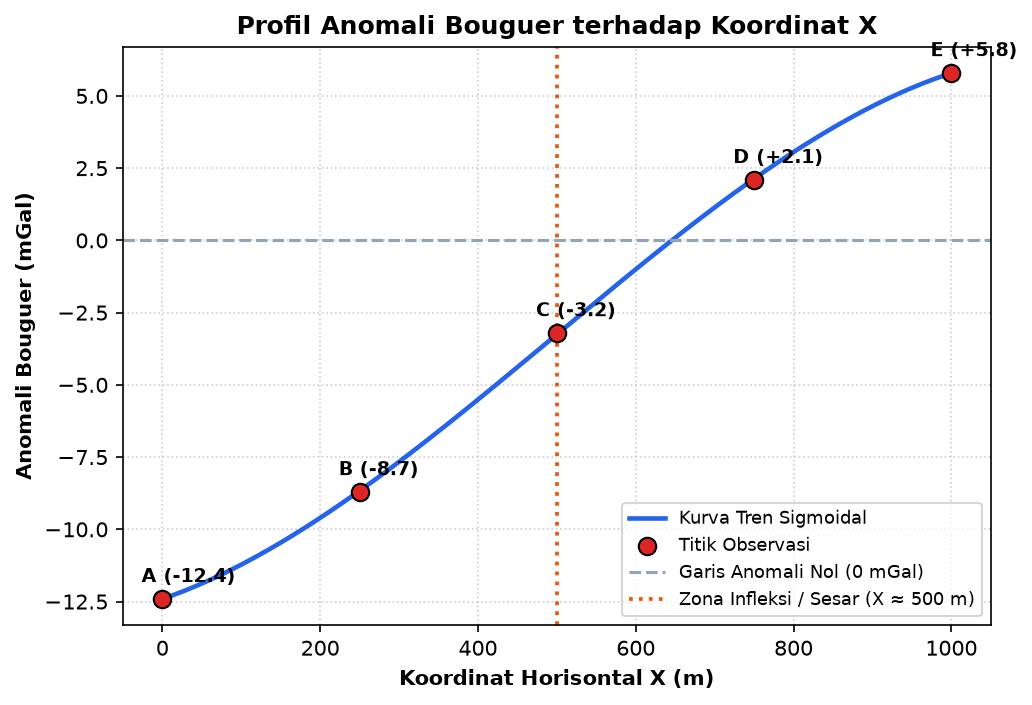

In [10]:
# Visualisasi Profil Anomali Bouguer dan Deteksi Bidang Sesar
fig, ax = plt.subplots(figsize=(7, 4.8), dpi=150)

# Fitting spline polinomial untuk memperhalus kurva sigmoidal
x_spline = np.linspace(0, 1000, 200)
poly_g = np.polyfit(x_grav, ba_grav, 3)
ba_spline = np.polyval(poly_g, x_spline)

ax.plot(x_spline, ba_spline, color='#2563eb', lw=2.2, label='Kurva Tren Sigmoidal')
ax.scatter(x_grav, ba_grav, color='#dc2626', s=70, edgecolors='black', zorder=5, label='Titik Observasi')
ax.axhline(0, color='#94a3b8', linestyle='--', label='Garis Anomali Nol (0 mGal)')
ax.axvline(500, color='#ea580c', linestyle=':', lw=1.8, label='Zona Infleksi / Sesar (X ≈ 500 m)')

for x_pt, b_pt, lbl in zip(x_grav, ba_grav, ['A', 'B', 'C', 'D', 'E']):
    ax.annotate(f"{lbl} ({b_pt:+.1f})", (x_pt, b_pt), textcoords="offset points", xytext=(-10, 8), fontweight='bold', fontsize=9)

ax.set_xlabel("Koordinat Horisontal X (m)", fontweight='bold')
ax.set_ylabel("Anomali Bouguer (mGal)", fontweight='bold')
ax.set_title("Profil Anomali Bouguer terhadap Koordinat X", fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()


## KESIMPULAN UMUM

| Modul | Metode Geofisika | Parameter Utama Terhitung | Temuan Fisis & Interpretasi |
| :---: | :--- | :--- | :--- |
| **1** | Seismologi Waktu Tiba | $X=35\text{ km}, Y=40\text{ km}, Z=15\text{ km}, T_0=10\text{ s}$ | Gempa tektonik dangkal, terverifikasi bebas trade-off |
| **2** | Gradien Geotermal | Rata-rata = $40{,}0\text{ °C/km}$ ($R^2 = 0{,}998$) | Rezim konduktif stabil dengan anomali aliran panas lokal |
| **3** | Pemrosesan Sinyal | Dominan: $5{,}0\text{ Hz}$, Sekunder: $15{,}0\text{ Hz}$ | Puncak spektral terisolasi murni di bawah Nyquist 50 Hz |
| **4** | Geolistrik 1D | 4 lapisan, tipe kurva HA | Palung konduktif dangkal (2,5–8,5 m) di atas batuan dasar masif |
| **5** | Gaya Berat | Total $\Delta BA = +18{,}2\text{ mGal}$, puncak $X=500\text{ m}$ | Struktur patahan turun vertikal / batas cekungan sedimen |

---
*Laporan praktikum komputasi ini diselesaikan secara mandiri menggunakan ekosistem Python ilmiah (NumPy, SciPy, Matplotlib).*
